# Machine Learning for Weekly Equity-Index Returns


## Imports and Dataset Loading

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn import svm
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error)
import tensorflow as tf

warnings.filterwarnings("ignore")

# Weekly MSCI international equity indices, 2016-2020.
# The csv file must be in the working directory.
# utf-8-sig removes the BOM character that Excel adds in front of "Date"
data_df = pd.read_csv("../../data/weekly_msci_indices.csv", encoding="utf-8-sig")
data_df["Date"] = pd.to_datetime(data_df["Date"], format="%d-%b-%y")
data_df = data_df.set_index("Date")

print("Dataset shape:", data_df.shape)
print("\nFirst rows:")
print(data_df.iloc[:3, :4])

Dataset shape: (252, 35)

First rows:
               LUXXX  MSCI ARGENTINA  BLP ORIENTE MEDIO  MSCI AUSTRALIA
Date                                                                   
2016-01-01  1390.716         2376.29          3525.9150         1068.79
2016-01-08  1291.267         2260.85          3280.6683         1005.56
2016-01-15  1257.086         2217.50          3118.2981          985.38


## Creation of the Target and the Features

In [2]:
# Regression problem: predict next week's return of the Luxembourg
# index (LUXXX) from the current weekly returns of the other 34 indices
reg_df = data_df.pct_change().dropna()
reg_df["Fwd_Return"] = reg_df["LUXXX"].shift(-1)
reg_df = reg_df.dropna()

reg_features = [c for c in reg_df.columns if c not in ["Fwd_Return", "LUXXX"]]

# Time ordered 80/20 split, scaler fitted on the training window only
train_sz_r = int(0.8 * len(reg_df))

sc_r = StandardScaler()
X_train_r = sc_r.fit_transform(reg_df[reg_features].iloc[:train_sz_r])
X_test_r = sc_r.transform(reg_df[reg_features].iloc[train_sz_r:])

y_train_r = reg_df["Fwd_Return"].values[:train_sz_r]
y_test_r = reg_df["Fwd_Return"].values[train_sz_r:]

print("Training observations:", len(X_train_r))
print("Test observations:", len(X_test_r))
print("Number of features:", X_train_r.shape[1])

Training observations: 200
Test observations: 50
Number of features: 34


## Baseline: Ordinary Least Squares

In [3]:
# Unpenalized regression as the benchmark
ols = LinearRegression()
ols.fit(X_train_r, y_train_r)

print("OLS train R2:", round(ols.score(X_train_r, y_train_r), 3))
print("OLS test R2:", round(ols.score(X_test_r, y_test_r), 3))
print("OLS test MSE:",
      round(mean_squared_error(y_test_r, ols.predict(X_test_r)), 6))

OLS train R2: 0.218
OLS test R2: -0.28
OLS test MSE: 0.003228


## LASSO with Cross Validated Alpha

In [4]:
# LassoCV selects the penalty alpha by 5-fold cross validation
lasso = LassoCV(alphas=np.logspace(-5, 0, 100), cv=5, random_state=0)
lasso.fit(X_train_r, y_train_r)

print("Selected alpha:", round(lasso.alpha_, 5))

n_selected = np.sum(lasso.coef_ != 0)
print("Features selected:", n_selected, "out of", len(reg_features))

print("\nLASSO train R2:", round(lasso.score(X_train_r, y_train_r), 3))
print("LASSO test R2:", round(lasso.score(X_test_r, y_test_r), 3))
print("LASSO test MSE:",
      round(mean_squared_error(y_test_r, lasso.predict(X_test_r)), 6))

Selected alpha: 1.0
Features selected: 0 out of 34

LASSO train R2: 0.0
LASSO test R2: -0.01
LASSO test MSE: 0.002549


## Shrinkage of the Coefficients

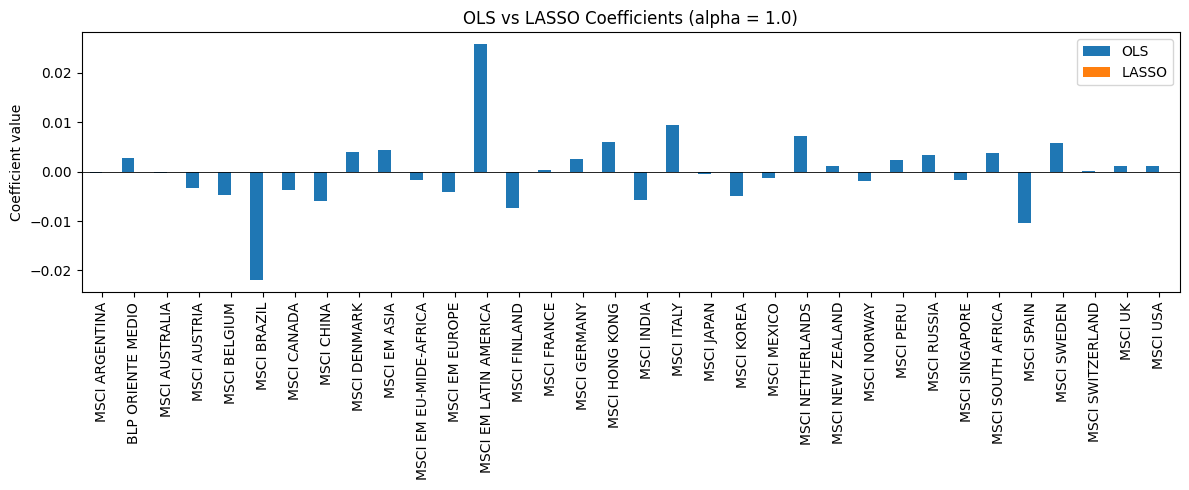

Coefficients kept by LASSO:
None - the penalty shrank every coefficient to zero


In [5]:
# Compare OLS and LASSO coefficients side by side
coefs = pd.DataFrame({"OLS": ols.coef_, "LASSO": lasso.coef_},
                     index=reg_features)

coefs.plot(kind="bar", figsize=(12, 5), width=0.8)
plt.title("OLS vs LASSO Coefficients (alpha = " +
          str(round(lasso.alpha_, 4)) + ")")
plt.ylabel("Coefficient value")
plt.axhline(0, color="black", linewidth=0.6)
plt.tight_layout()
plt.show()

kept = coefs[coefs["LASSO"] != 0]["LASSO"].sort_values()
print("Coefficients kept by LASSO:")
print(kept.round(4) if len(kept) > 0
      else "None - the penalty shrank every coefficient to zero")

## Regularization Path of the Coefficients

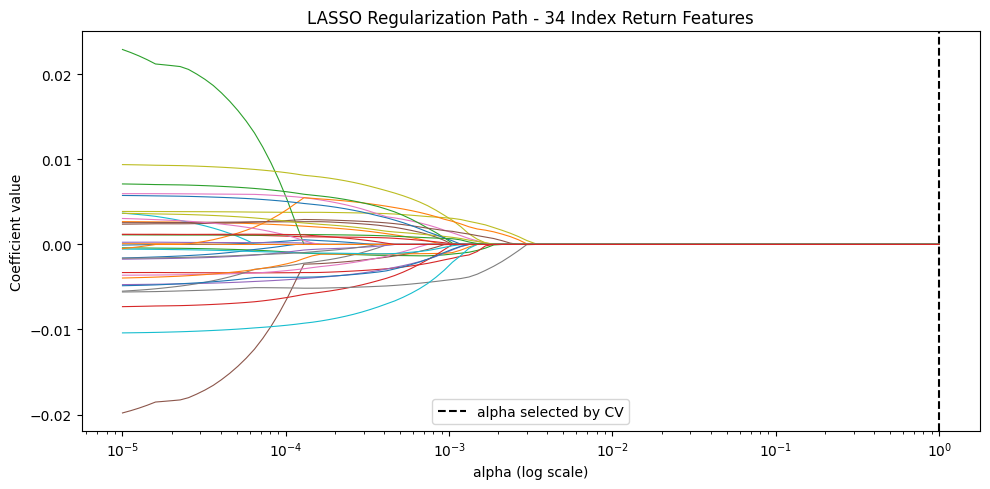

At the selected alpha every coefficient has been shrunk to zero,
so the cross validation prefers the intercept-only model.


In [6]:
from sklearn.linear_model import lasso_path

# How each coefficient shrinks as the penalty alpha grows
alphas_path, coefs_path, _ = lasso_path(X_train_r, y_train_r,
                                        alphas=np.logspace(-5, 0, 100))

plt.figure(figsize=(10, 5))
for i in range(coefs_path.shape[0]):
    plt.plot(alphas_path, coefs_path[i], linewidth=0.8)
plt.axvline(lasso.alpha_, color="black", linestyle="--",
            label="alpha selected by CV")
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("Coefficient value")
plt.title("LASSO Regularization Path - 34 Index Return Features")
plt.legend()
plt.tight_layout()
plt.show()

print("At the selected alpha every coefficient has been shrunk to zero,")
print("so the cross validation prefers the intercept-only model.")

*Note: the cross-validated α sits at the upper boundary of the search grid. The regularization path above shows that every coefficient is already zero from α ≈ 3×10⁻³ onwards, so extending the grid upward cannot change the intercept-only conclusion — the cross validation simply prefers no model over a noisy one.*

# Equity Market Clustering

## Preparation of the Data for Clustering

In [7]:
# Unsupervised problem: group the 35 markets by the similarity of their
# weekly return behaviour. Each observation is one country/region index,
# described by its standardized weekly log returns
returns = np.log(data_df / data_df.shift(1)).dropna()

km_input = StandardScaler().fit_transform(returns)
km_input = pd.DataFrame(km_input.T, index=returns.columns)

print("Clustering input shape (markets x weeks):", km_input.shape)

Clustering input shape (markets x weeks): (35, 251)


## Choosing k with the Elbow Method and the Silhouette Score

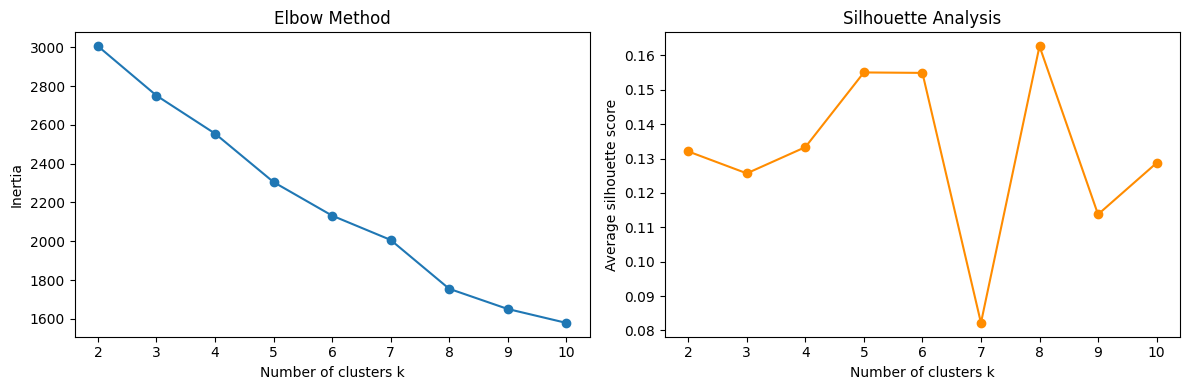

Silhouette scores by k:
2     0.132
3     0.126
4     0.133
5     0.155
6     0.155
7     0.082
8     0.163
9     0.114
10    0.129
dtype: float64

k selected by the silhouette criterion: 8


In [8]:
ks = range(2, 11)
inertias, silhouettes = [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels_k = km.fit_predict(km_input)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(km_input, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")
axes[1].plot(ks, silhouettes, marker="o", color="darkorange")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Average silhouette score")
axes[1].set_title("Silhouette Analysis")
plt.tight_layout()
plt.show()

best_k = ks[int(np.argmax(silhouettes))]
print("Silhouette scores by k:")
print(pd.Series(silhouettes, index=ks).round(3))
print("\nk selected by the silhouette criterion:", best_k)

## Fitting of the Final Model and Cluster Membership

In [9]:
kmeans = KMeans(n_clusters=best_k, random_state=0, n_init=10)
clusters = kmeans.fit_predict(km_input)

membership = pd.Series(clusters, index=km_input.index)

for c in range(best_k):
    members = membership[membership == c].index.tolist()
    print(f"Cluster {c} ({len(members)} markets):")
    print(", ".join(m.replace("MSCI ", "") for m in members))
    print()

Cluster 0 (15 markets):
LUXXX, AUSTRIA, BELGIUM, DENMARK, FINLAND, FRANCE, GERMANY, ITALY, JAPAN, NETHERLANDS, NORWAY, SPAIN, SWEDEN, SWITZERLAND, UK

Cluster 1 (3 markets):
BRAZIL, EM LATIN AMERICA, PERU

Cluster 2 (7 markets):
CHINA, EM ASIA, HONG KONG, INDIA, KOREA, SINGAPORE, SOUTH AFRICA

Cluster 3 (1 markets):
ARGENTINA

Cluster 4 (3 markets):
AUSTRALIA, CANADA, USA

Cluster 5 (1 markets):
BLP ORIENTE MEDIO

Cluster 6 (4 markets):
EM EU-MIDE-AFRICA, EM EUROPE, MEXICO, RUSSIA

Cluster 7 (1 markets):
NEW ZEALAND



## Visualization of the Clusters in Risk-Return Space

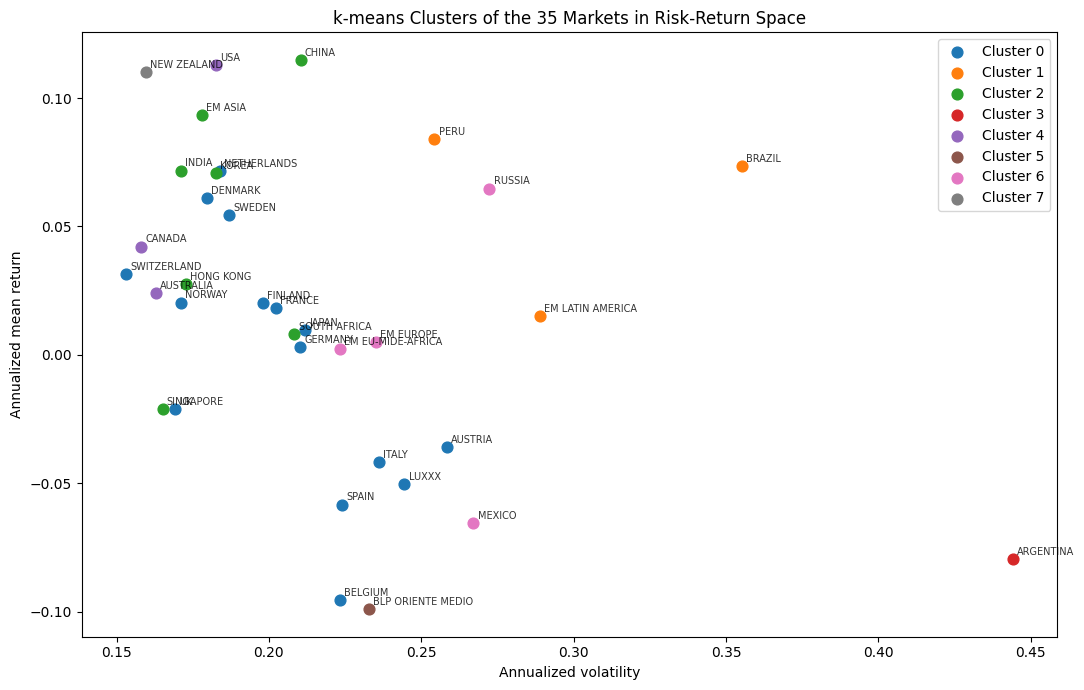

Average risk-return profile per cluster:
         Ann. return  Ann. volatility
Cluster                              
0             -0.001            0.203
1              0.058            0.299
2              0.052            0.184
3             -0.080            0.444
4              0.060            0.168
5             -0.099            0.233
6              0.002            0.249
7              0.110            0.160


In [10]:
# Annualized mean return and volatility of each market (52 weeks/year)
ann_ret = returns.mean() * 52
ann_vol = returns.std() * np.sqrt(52)

plt.figure(figsize=(11, 7))
for c in range(best_k):
    mask = membership == c
    plt.scatter(ann_vol[mask], ann_ret[mask], s=60, label=f"Cluster {c}")

for name in returns.columns:
    plt.annotate(name.replace("MSCI ", ""),
                 (ann_vol[name], ann_ret[name]),
                 fontsize=7, alpha=0.8,
                 xytext=(3, 3), textcoords="offset points")

plt.xlabel("Annualized volatility")
plt.ylabel("Annualized mean return")
plt.title("k-means Clusters of the 35 Markets in Risk-Return Space")
plt.legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame({"Ann. return": ann_ret, "Ann. volatility": ann_vol,
                        "Cluster": membership})
print("Average risk-return profile per cluster:")
print(summary.groupby("Cluster").mean().round(3))

# Principal Component Analysis

## Standardization of the Log Returns

In [11]:
# PCA uses the weekly log returns computed in the clustering section,
# standardized to mean 0 and std 1
scaler = StandardScaler()
X_std = scaler.fit_transform(returns)
X_std = pd.DataFrame(X_std, index=returns.index, columns=returns.columns)

print("Return matrix shape:", returns.shape)
print("\nMean after standardization:")
print(X_std.mean().round(3).head())
print("\nStd after standardization:")
print(X_std.std().round(3).head())

Return matrix shape: (251, 35)

Mean after standardization:
LUXXX               -0.0
MSCI ARGENTINA       0.0
BLP ORIENTE MEDIO   -0.0
MSCI AUSTRALIA      -0.0
MSCI AUSTRIA         0.0
dtype: float64

Std after standardization:
LUXXX                1.002
MSCI ARGENTINA       1.002
BLP ORIENTE MEDIO    1.002
MSCI AUSTRALIA       1.002
MSCI AUSTRIA         1.002
dtype: float64


## Fitting of the PCA Model

In [12]:
pca = PCA()
scores = pca.fit_transform(X_std)

evr = pca.explained_variance_ratio_
cum_evr = np.cumsum(evr)

variance = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(5)],
    "Eigenvalue": pca.explained_variance_[:5].round(2),
    "Explained Variance": evr[:5].round(3),
    "Cumulative Variance": cum_evr[:5].round(3),
})
print(variance)

print("\nComponents needed for 80% of total variance:",
      np.argmax(cum_evr >= 0.80) + 1)

  Component  Eigenvalue  Explained Variance  Cumulative Variance
0       PC1       21.28               0.606                0.606
1       PC2        2.56               0.073                0.679
2       PC3        1.35               0.038                0.717
3       PC4        1.13               0.032                0.749
4       PC5        0.96               0.027                0.776

Components needed for 80% of total variance: 7


## Scree Plot and Explained Variance

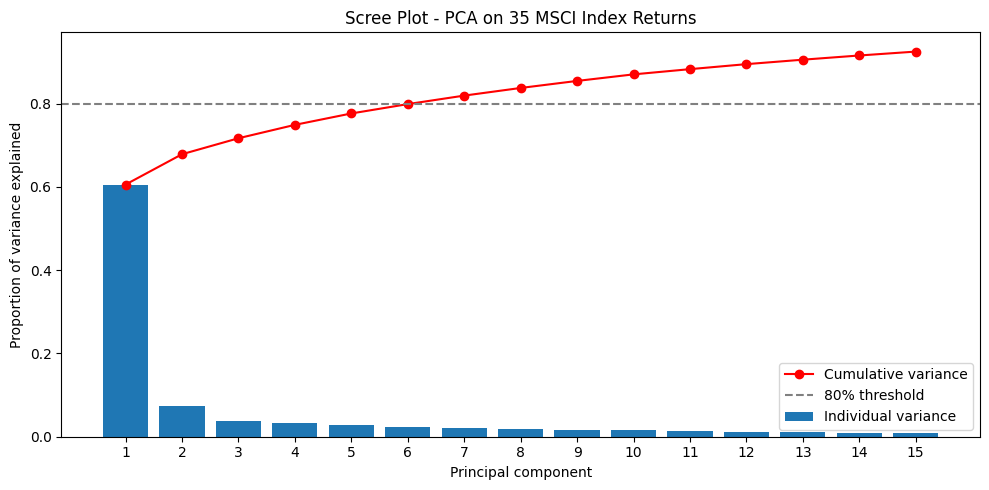

PC1 alone explains: 60.6 % of total variance
First 3 PCs explain: 71.7 %


In [13]:
n_show = 15

plt.figure(figsize=(10, 5))
plt.bar(range(1, n_show + 1), evr[:n_show], label="Individual variance")
plt.plot(range(1, n_show + 1), cum_evr[:n_show], color="red", marker="o",
         label="Cumulative variance")
plt.axhline(0.80, color="grey", linestyle="--", label="80% threshold")
plt.xlabel("Principal component")
plt.ylabel("Proportion of variance explained")
plt.title("Scree Plot - PCA on 35 MSCI Index Returns")
plt.xticks(range(1, n_show + 1))
plt.legend()
plt.tight_layout()
plt.show()

print("PC1 alone explains:", round(evr[0] * 100, 1), "% of total variance")
print("First 3 PCs explain:", round(cum_evr[2] * 100, 1), "%")

## Loadings of the Principal Components

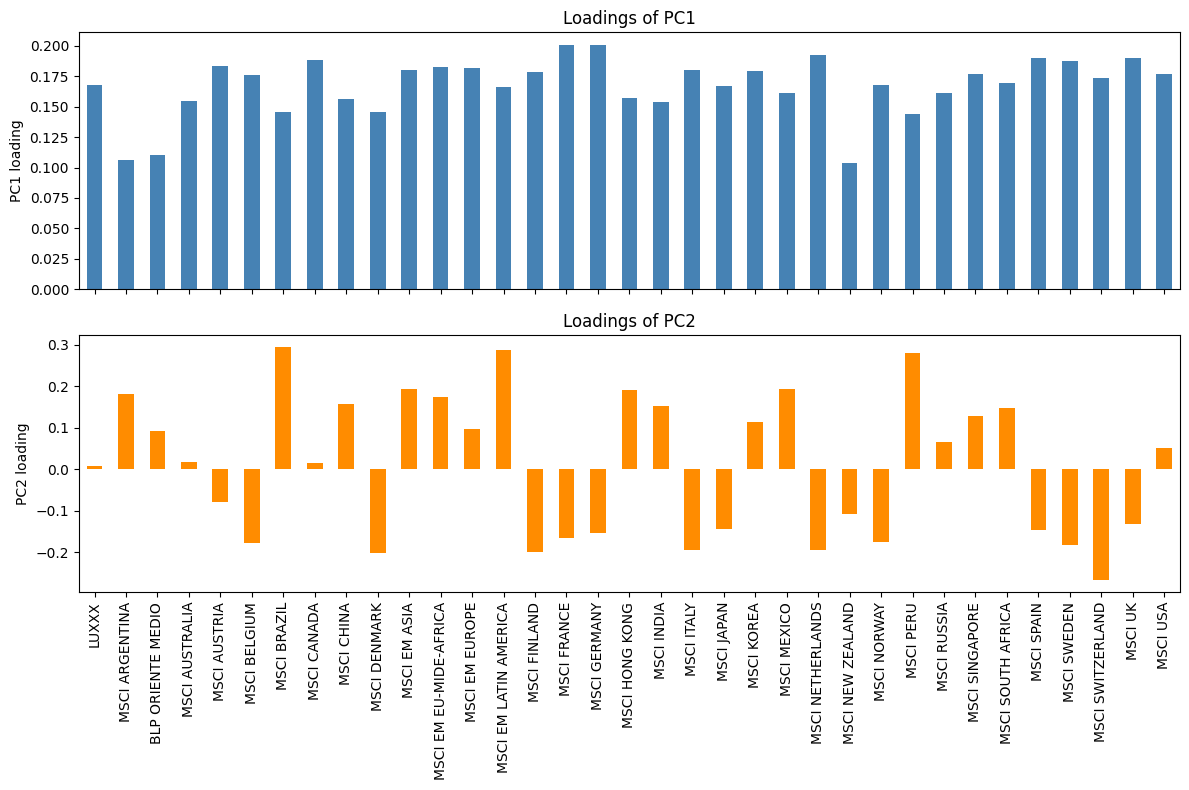

Most positive PC2 loadings:
MSCI BRAZIL              0.295
MSCI EM LATIN AMERICA    0.288
MSCI PERU                0.279
MSCI MEXICO              0.193
MSCI EM ASIA             0.193
Name: PC2, dtype: float64

Most negative PC2 loadings:
MSCI SWITZERLAND   -0.268
MSCI DENMARK       -0.201
MSCI FINLAND       -0.201
MSCI ITALY         -0.196
MSCI NETHERLANDS   -0.195
Name: PC2, dtype: float64


In [14]:
loadings = pd.DataFrame(pca.components_.T, index=returns.columns,
                        columns=[f"PC{i+1}" for i in range(pca.n_components_)])

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
loadings["PC1"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Loadings of PC1")
axes[0].set_ylabel("PC1 loading")
loadings["PC2"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_ylabel("PC2 loading")
axes[1].set_title("Loadings of PC2")
plt.tight_layout()
plt.show()

print("Most positive PC2 loadings:")
print(loadings["PC2"].sort_values(ascending=False).head(5).round(3))
print("\nMost negative PC2 loadings:")
print(loadings["PC2"].sort_values().head(5).round(3))

## Time Series and Reconstruction from Three Components

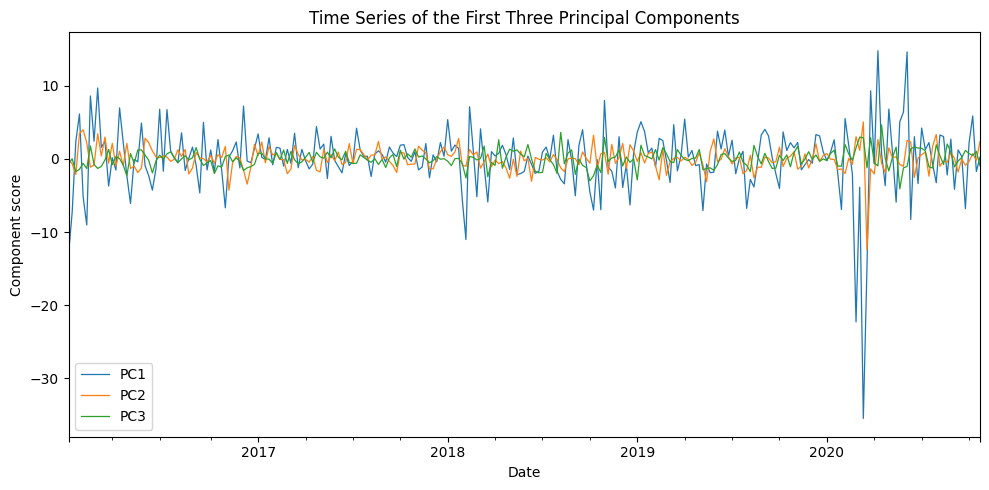

Mean squared reconstruction error with k = 3 : 0.283
Variance retained: 71.7 %


In [15]:
scores_df = pd.DataFrame(scores[:, :3], index=returns.index,
                         columns=["PC1", "PC2", "PC3"])

scores_df.plot(figsize=(10, 5), linewidth=0.9)
plt.title("Time Series of the First Three Principal Components")
plt.xlabel("Date")
plt.ylabel("Component score")
plt.tight_layout()
plt.show()

k = 3
X_hat = scores[:, :k] @ pca.components_[:k, :]
reconstruction_error = np.mean((X_std.values - X_hat) ** 2)

print("Mean squared reconstruction error with k =", k, ":",
      round(reconstruction_error, 3))
print("Variance retained:", round(cum_evr[k - 1] * 100, 1), "%")

# Decision Trees for Return Classification

## Creation of the Target and the Features

In [16]:
# Classification problem shared with Category 6: predict whether next
# week's LUXXX return moves by more than 2.5% in absolute value
clf_df = data_df.pct_change().dropna()
clf_df["Fwd_Return"] = clf_df["LUXXX"].shift(-1)
clf_df = clf_df.dropna()

y_clf = np.where(clf_df["Fwd_Return"].abs() > 0.025, 1, 0)
X_clf = clf_df.drop(columns=["Fwd_Return", "LUXXX"])

# so the unscaled split is kept and reused by the SVM in Category 6
# so Categories 4-6 remain directly comparable with each other. Because the
# target is next week's return, a strictly time-ordered split (as used in
# Categories 1 and 7) is the more conservative choice for a deployment-grade
# backtest; results here should be read as a model comparison, not a backtest.
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=0)

print("Feature matrix shape:", X_clf.shape)
print("\nTarget distribution:")
print(pd.Series(y_clf).value_counts())

Feature matrix shape: (250, 34)

Target distribution:
0    164
1     86
Name: count, dtype: int64


## Baseline: Tree Grown to Full Depth

In [17]:
# Unrestricted tree to show the overfitting problem
full_tree = DecisionTreeClassifier(random_state=0)
full_tree.fit(X_train_c, y_train_c)

print("Full tree depth:", full_tree.get_depth())
print("Training accuracy:", round(full_tree.score(X_train_c, y_train_c), 3))
print("Test accuracy:", round(full_tree.score(X_test_c, y_test_c), 3))

Full tree depth: 9
Training accuracy: 1.0
Test accuracy: 0.66


## Hyperparameter Tuning of the Tree

In [18]:
tree_grid_params = {
    "max_depth": [1, 2, 3, 4, 5, 6, 8, 10],
    "min_samples_leaf": [1, 5, 10, 20],
}

# Balanced class weights and F1 scoring, consistent with Category 6
tree_grid = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=0),
    tree_grid_params, refit=True, verbose=1, cv=5, scoring="f1")
tree_grid.fit(X_train_c, y_train_c)

print("\nBest parameters:", tree_grid.best_params_)
print("Best cross validation F1:", round(tree_grid.best_score_, 3))

tree_pred = tree_grid.predict(X_test_c)

print("\nTest accuracy:", round(accuracy_score(y_test_c, tree_pred), 3))
print("\nClassification report:")
print(classification_report(y_test_c, tree_pred,
                            target_names=["Small Move", "Big Move"]))

Fitting 5 folds for each of 32 candidates, totalling 160 fits

Best parameters: {'max_depth': 5, 'min_samples_leaf': 10}
Best cross validation F1: 0.454

Test accuracy: 0.48

Classification report:
              precision    recall  f1-score   support

  Small Move       0.72      0.49      0.58        37
    Big Move       0.24      0.46      0.32        13

    accuracy                           0.48        50
   macro avg       0.48      0.47      0.45        50
weighted avg       0.60      0.48      0.51        50



## Visualization of the Fitted Tree

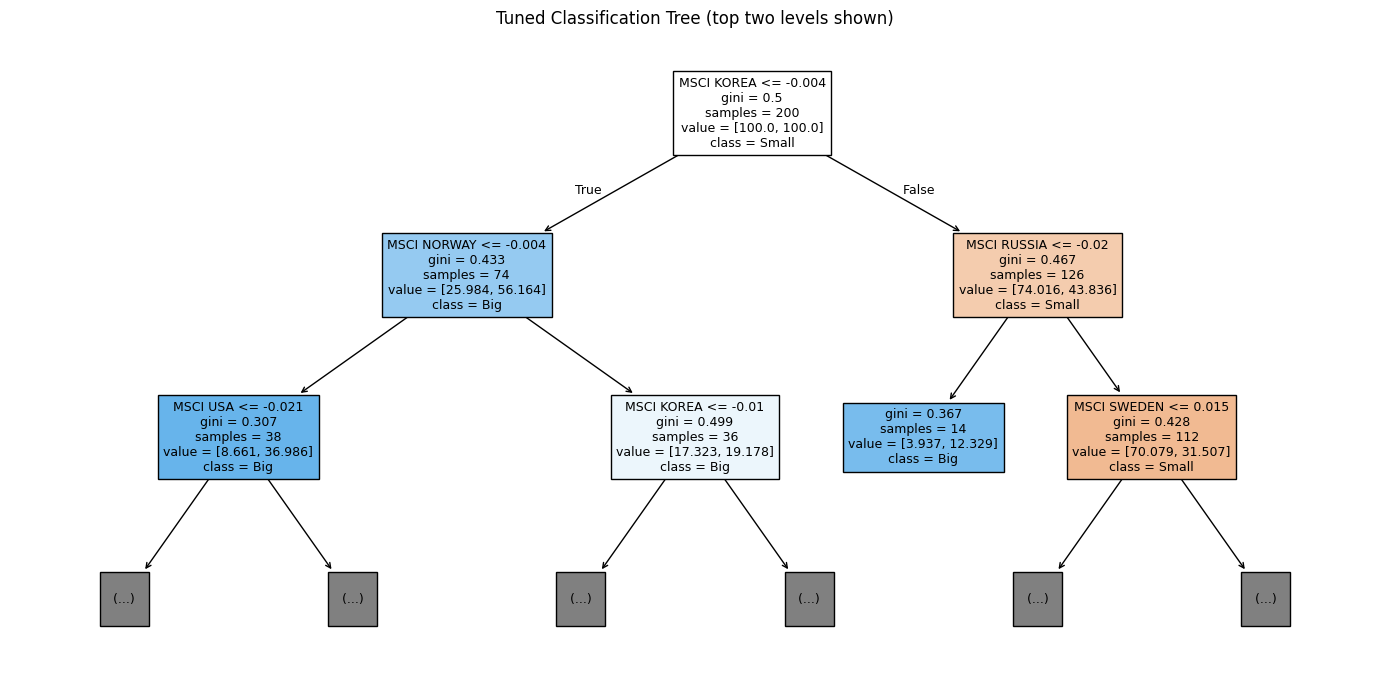

In [19]:
plt.figure(figsize=(14, 7))
plot_tree(tree_grid.best_estimator_, max_depth=2,
          feature_names=X_clf.columns, class_names=["Small", "Big"],
          filled=True, fontsize=9)
plt.title("Tuned Classification Tree (top two levels shown)")
plt.tight_layout()
plt.show()

## Feature Importances

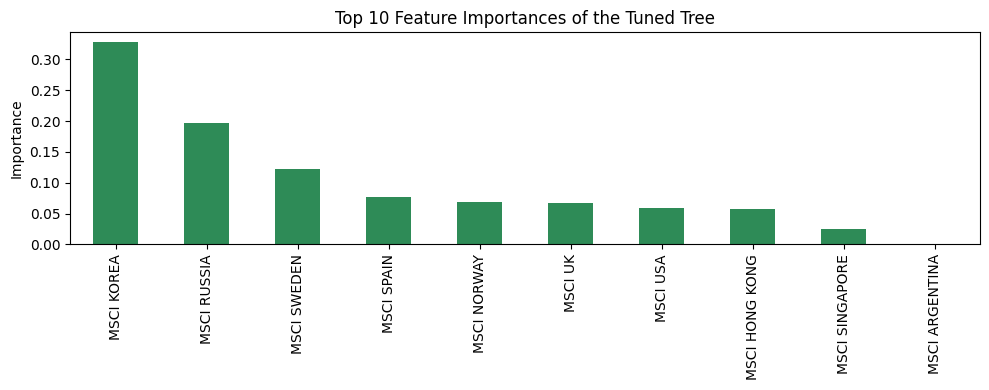

Top five features:
MSCI KOREA     0.328
MSCI RUSSIA    0.197
MSCI SWEDEN    0.122
MSCI SPAIN     0.077
MSCI NORWAY    0.068
dtype: float64


In [20]:
importances = pd.Series(tree_grid.best_estimator_.feature_importances_,
                        index=X_clf.columns).sort_values(ascending=False)

importances.head(10).plot(kind="bar", figsize=(10, 4), color="seagreen")
plt.title("Top 10 Feature Importances of the Tuned Tree")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

print("Top five features:")
print(importances.head(5).round(3))

# Linear Discriminant Analysis

## Fitting the LDA Model

In [21]:
# LDA on the same big-move classification problem and the same
# train/test split used by the tree (Category 4) and the SVM (Category 6),
# so all three classifiers are directly comparable.
# LDA estimates one Gaussian per class with a shared covariance matrix
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_c, y_train_c)

print("Class priors estimated from the training data:")
print(pd.Series(lda.priors_, index=["Small Move", "Big Move"]).round(3))

print("\nTraining accuracy:", round(lda.score(X_train_c, y_train_c), 3))
print("Test accuracy:", round(lda.score(X_test_c, y_test_c), 3))

Class priors estimated from the training data:
Small Move    0.635
Big Move      0.365
dtype: float64

Training accuracy: 0.74
Test accuracy: 0.56


## Evaluation of the Model

Classification report:
              precision    recall  f1-score   support

  Small Move       0.71      0.68      0.69        37
    Big Move       0.20      0.23      0.21        13

    accuracy                           0.56        50
   macro avg       0.46      0.45      0.45        50
weighted avg       0.58      0.56      0.57        50



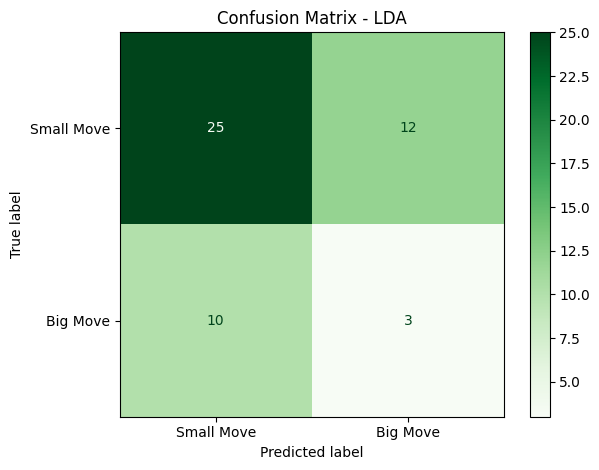

In [22]:
lda_pred = lda.predict(X_test_c)

print("Classification report:")
print(classification_report(y_test_c, lda_pred,
                            target_names=["Small Move", "Big Move"]))

cm = confusion_matrix(y_test_c, lda_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Small Move", "Big Move"])
disp.plot(cmap="Greens")
plt.title("Confusion Matrix - LDA")
plt.tight_layout()
plt.show()

## Separation of the Classes on the Discriminant Axis

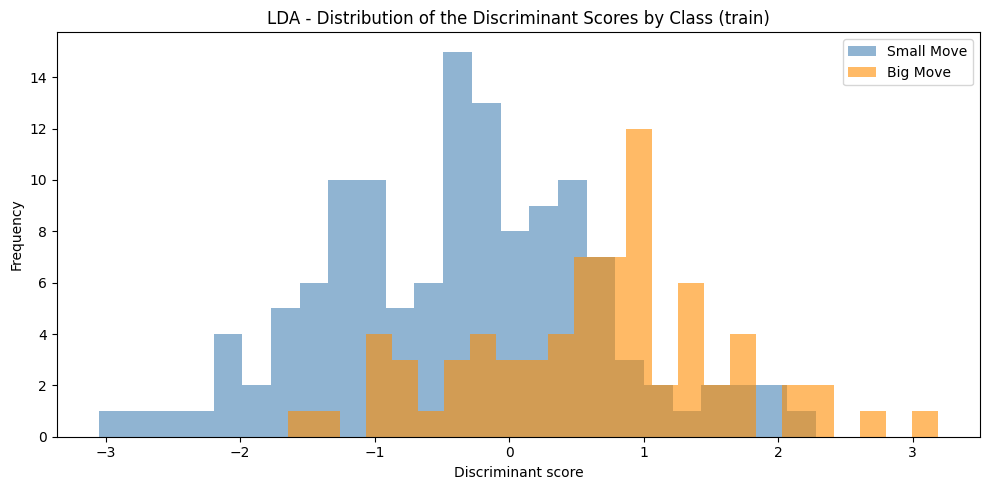

In [23]:
# For two classes LDA reduces the 34 features to a single discriminant
# score; the histograms show how well the two classes separate on it
scores_train = lda.transform(X_train_c).squeeze()

plt.figure(figsize=(10, 5))
plt.hist(scores_train[y_train_c == 0], bins=25, alpha=0.6,
         label="Small Move", color="steelblue")
plt.hist(scores_train[y_train_c == 1], bins=25, alpha=0.6,
         label="Big Move", color="darkorange")
plt.xlabel("Discriminant score")
plt.ylabel("Frequency")
plt.title("LDA - Distribution of the Discriminant Scores by Class (train)")
plt.legend()
plt.tight_layout()
plt.show()

# Support Vector Machines

## Feature Standardization

In [24]:
# The SVM uses the same target and the same train/test split as the
# classification tree, so the two models are directly comparable.
# Unlike trees, the SVM requires standardized features
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train_c)
X_test_s = sc.transform(X_test_c)

# Baseline SVM with default settings
baseline = svm.SVC(kernel="rbf")
baseline.fit(X_train_s, y_train_c)

print("Training accuracy:", round(baseline.score(X_train_s, y_train_c), 3))
print("Test accuracy:", round(baseline.score(X_test_s, y_test_c), 3))

Training accuracy: 0.775
Test accuracy: 0.76


## Hyperparameter Tuning with Grid Search

In [25]:
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100, 1000],
    "kernel": ["rbf", "linear", "poly"],
}

# Balanced class weights because big moves are the minority class,
# and F1 scoring so the search does not select a majority-class model
grid = GridSearchCV(svm.SVC(class_weight="balanced"), param_grid,
                    refit=True, verbose=1, cv=5, scoring="f1")
grid.fit(X_train_s, y_train_c)

print("\nBest parameters:", grid.best_params_)
print("Best estimator:", grid.best_estimator_)
print("Best cross validation F1:", round(grid.best_score_, 3))

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best parameters: {'C': 1, 'kernel': 'rbf'}
Best estimator: SVC(C=1, class_weight='balanced')
Best cross validation F1: 0.498


## Evaluation of the Tuned Model

Test accuracy: 0.64

Classification report:
              precision    recall  f1-score   support

  Small Move       0.85      0.62      0.72        37
    Big Move       0.39      0.69      0.50        13

    accuracy                           0.64        50
   macro avg       0.62      0.66      0.61        50
weighted avg       0.73      0.64      0.66        50



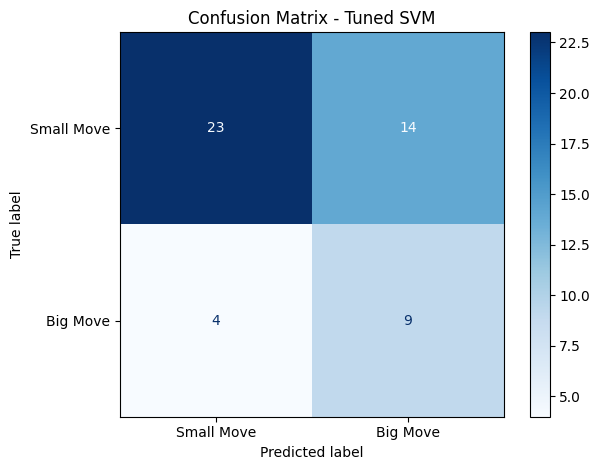

In [26]:
prediction = grid.predict(X_test_s)

print("Test accuracy:", round(accuracy_score(y_test_c, prediction), 3))
print("\nClassification report:")
print(classification_report(y_test_c, prediction,
                            target_names=["Small Move", "Big Move"]))

cm = confusion_matrix(y_test_c, prediction)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Small Move", "Big Move"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Tuned SVM")
plt.tight_layout()
plt.show()

## Contrast: What Accuracy Scoring Would Have Selected

In [27]:
from sklearn.metrics import f1_score

# Same grid, but scored by plain accuracy and without balanced class
# weights: cross validation now selects a degenerate model that predicts
# "Small Move" every single week - the headline accuracy equals the
# majority-class share of the test set, but recall on big moves is zero.
# This motivates the F1 scoring and balanced weights used above.
grid_acc = GridSearchCV(svm.SVC(), param_grid,
                        refit=True, cv=5, scoring="accuracy")
grid_acc.fit(X_train_s, y_train_c)

pred_acc = grid_acc.predict(X_test_s)
print("Best parameters (accuracy scoring):", grid_acc.best_params_)
print("Test accuracy:", round(accuracy_score(y_test_c, pred_acc), 3))
print("F1 (Big Move):", round(f1_score(y_test_c, pred_acc), 3))
print("Predicted class counts [Small, Big]:",
      np.bincount(pred_acc, minlength=2))


Best parameters (accuracy scoring): {'C': 0.01, 'kernel': 'rbf'}
Test accuracy: 0.74
F1 (Big Move): 0.0
Predicted class counts [Small, Big]: [50  0]


## Comparison of the SVM, the Tree and the LDA on the Same Test Set

In [28]:
from sklearn.metrics import f1_score

comparison = pd.DataFrame({
    "Accuracy": [round(accuracy_score(y_test_c, prediction), 3),
                 round(accuracy_score(y_test_c, tree_pred), 3),
                 round(accuracy_score(y_test_c, lda_pred), 3)],
    "F1 (Big Move)": [round(f1_score(y_test_c, prediction), 3),
                      round(f1_score(y_test_c, tree_pred), 3),
                      round(f1_score(y_test_c, lda_pred), 3)],
}, index=["Tuned SVM", "Tuned Tree", "LDA"])

print("Comparison on the same test set:")
print(comparison)

Comparison on the same test set:
            Accuracy  F1 (Big Move)
Tuned SVM       0.64          0.500
Tuned Tree      0.48          0.316
LDA             0.56          0.214


# Neural Network Forecasting

## Preparation and Scaling of the Dataset

In [29]:
# Regression problem: predict next week's LUXXX return, as in the penalized regression section
nn_df = data_df.pct_change().dropna()
nn_df["Fwd_Return"] = nn_df["LUXXX"].shift(-1)
nn_df = nn_df.dropna()

features = [c for c in nn_df.columns if c not in ["Fwd_Return", "LUXXX"]]

# Time ordered 80/20 split, then min max scaling fitted on the
# training window only, to avoid using future information
train_sz = int(0.8 * len(nn_df))

mm = MinMaxScaler()
X_train_nn = mm.fit_transform(nn_df[features].iloc[:train_sz])
X_test_nn = mm.transform(nn_df[features].iloc[train_sz:])

y_train_nn = nn_df["Fwd_Return"].values[:train_sz]
y_test_nn = nn_df["Fwd_Return"].values[train_sz:]

print("Training observations:", len(X_train_nn))
print("Test observations:", len(X_test_nn))
print("Number of input features:", X_train_nn.shape[1])

Training observations: 200
Test observations: 50
Number of input features: 34


## Building and Training of a Baseline Network

In [30]:
tf.random.set_seed(42)

model = tf.keras.Sequential([tf.keras.layers.Dense(1)])

model.compile(loss="mae",
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.01,
                                                momentum=0.9),
              metrics=["mae"])

model.fit(X_train_nn, y_train_nn, epochs=10, batch_size=8, verbose=0)

preds = model.predict(X_test_nn, verbose=0)

print("Test mean absolute error:",
      round(mean_absolute_error(y_test_nn, preds.squeeze()), 4))
print("Test mean squared error:",
      round(mean_squared_error(y_test_nn, preds.squeeze()), 5))

Test mean absolute error: 0.1014
Test mean squared error: 0.01378


## Improvement of the Model with Hidden Layers

In [31]:
# More epochs, added extra layers, Adam optimizer
tf.random.set_seed(42)

model_1 = tf.keras.Sequential([
    tf.keras.layers.Dense(8, activation="sigmoid",
                          input_shape=(X_train_nn.shape[1],)),
    tf.keras.layers.Dense(4, activation="sigmoid"),
    tf.keras.layers.Dense(1),
])

model_1.compile(loss="mae",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["mae"])

model_1.fit(X_train_nn, y_train_nn, epochs=100, batch_size=8, verbose=0)

model_1.summary()

preds_1 = model_1.predict(X_test_nn, verbose=0)

print("\nTest mean absolute error:",
      round(mean_absolute_error(y_test_nn, preds_1.squeeze()), 4))
print("Test mean squared error:",
      round(mean_squared_error(y_test_nn, preds_1.squeeze()), 5))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 8)              │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 965 (3.77 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 644 (2.52 KB)


Test mean absolute error: 0.0424
Test mean squared error: 0.00412


## Comparison with a Naive Zero-Return Benchmark

In [32]:
# An honest benchmark: how well does simply predicting a zero
# return do on the same test window?
naive_mae = mean_absolute_error(y_test_nn, np.zeros_like(y_test_nn))
nn_mae = mean_absolute_error(y_test_nn, preds_1.squeeze())

print("Naive 'always predict zero' MAE:", round(naive_mae, 4))
print("Deep neural network MAE:", round(nn_mae, 4))

if nn_mae < naive_mae:
    print("\nThe network beats the naive benchmark only marginally,")
else:
    print("\nThe network does not beat the naive benchmark,")
print("so the honest conclusion is that weekly index returns are")
print("close to unpredictable, consistent with Categories 1 and 6.")

Naive 'always predict zero' MAE: 0.0353
Deep neural network MAE: 0.0424

The network does not beat the naive benchmark,
so the honest conclusion is that weekly index returns are
close to unpredictable, consistent with Categories 1 and 6.


## Predictions Against the Actual Returns

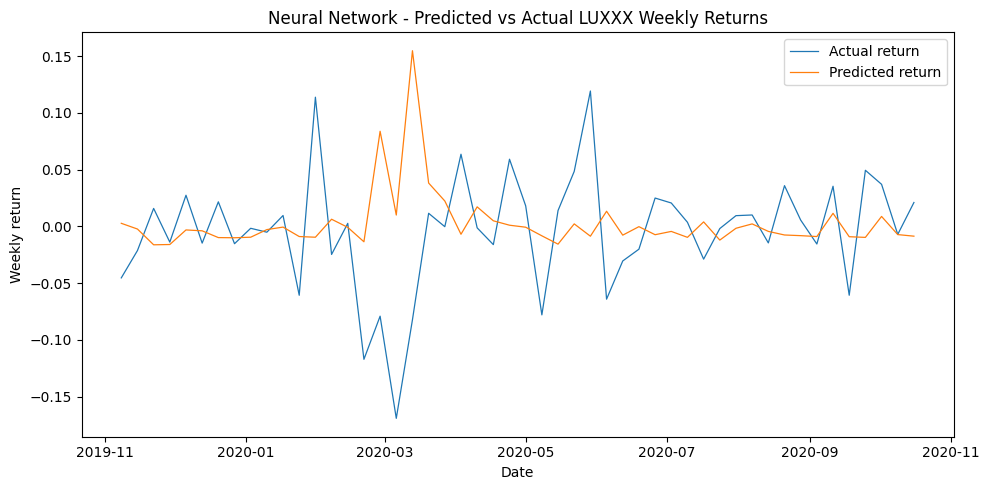

In [33]:
test_dates = nn_df.index[train_sz:]

plt.figure(figsize=(10, 5))
plt.plot(test_dates, y_test_nn, label="Actual return", linewidth=0.9)
plt.plot(test_dates, preds_1.squeeze(), label="Predicted return",
         linewidth=0.9)
plt.title("Neural Network - Predicted vs Actual LUXXX Weekly Returns")
plt.xlabel("Date")
plt.ylabel("Weekly return")
plt.legend()
plt.tight_layout()
plt.show()